# RadJEPA3D demo

Questo notebook mostra come funziona il passaggio principale della pipeline:

```text
volume CT preprocessato (.npy)
  -> RadJEPA3D frozen encoder
  -> token embeddings [N, D]
  -> mean-pooled embedding [D]
```

Il notebook riusa le funzioni di `scripts/extract_radjepa_embeddings.py`, quindi usa esattamente lo stesso caricamento modello della pipeline server.

## Requisiti

Per eseguire la forward pass reale servono:

- codice RadJEPA originale in `external/RadJepa/`
- checkpoint HuggingFace in `external/Rad-Jepa-3D-hf/`
- dipendenze CUDA/RadJEPA installate, in particolare `mamba_ssm`

Su macOS la parte di visualizzazione del volume funziona, ma la forward pass RadJEPA3D potrebbe non partire se `mamba_ssm` non e disponibile. Sul server CUDA dovrebbe essere il contesto giusto.

In [1]:
from pathlib import Path
import sys
import os

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

repo_root = Path.cwd()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent

sys.path.insert(0, str(repo_root))

print("repo_root:", repo_root)
print("torch:", torch.__version__)
print("cuda_available:", torch.cuda.is_available())

repo_root: /home/domenico/lung-jepa-world-model
torch: 2.5.1+cu121
cuda_available: True


In [2]:
# Modifica questi path se vuoi puntare a un dataset diverso.
manifest_candidates = [
    Path("/ssd2/domenico/datasets/nlst/processed/nlst/pilot_1460_balanced/radjepa_npy_manifest.csv"),
    Path("/ssd2/domenico/datasets/nlst/processed/nlst/pilot_500_balanced/radjepa_npy_manifest.csv"),
    repo_root / "data/processed/nlst/pilot_500_balanced/radjepa_npy_manifest.csv",
    repo_root / "data/processed/nlst/radjepa_npy_manifest.csv",
]

radjepa_code_dir = repo_root / "external/RadJepa"
hf_model_dir = repo_root / "external/Rad-Jepa-3D-hf"
config_path = hf_model_dir / "config.json"
checkpoint_path = hf_model_dir / "encoder/encoder.pt"
output_dir = repo_root / "outputs/notebook_radjepa3d_demo"
output_dir.mkdir(parents=True, exist_ok=True)

input_manifest = next((p for p in manifest_candidates if p.exists()), None)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("input_manifest:", input_manifest)
print("radjepa_code_dir:", radjepa_code_dir, radjepa_code_dir.exists())
print("hf_model_dir:", hf_model_dir, hf_model_dir.exists())
print("config_path:", config_path, config_path.exists())
print("checkpoint_path:", checkpoint_path, checkpoint_path.exists())
print("device:", device)
print("output_dir:", output_dir)

input_manifest: /ssd2/domenico/datasets/nlst/processed/nlst/pilot_500_balanced/radjepa_npy_manifest.csv
radjepa_code_dir: /home/domenico/lung-jepa-world-model/external/RadJepa True
hf_model_dir: /home/domenico/lung-jepa-world-model/external/Rad-Jepa-3D-hf True
config_path: /home/domenico/lung-jepa-world-model/external/Rad-Jepa-3D-hf/config.json True
checkpoint_path: /home/domenico/lung-jepa-world-model/external/Rad-Jepa-3D-hf/encoder/encoder.pt True
device: cuda
output_dir: /home/domenico/lung-jepa-world-model/outputs/notebook_radjepa3d_demo


## Architettura RadJEPA3D

Se disponibile localmente, la cella seguente mostra lo schema dell'architettura distribuito insieme al checkpoint HuggingFace.

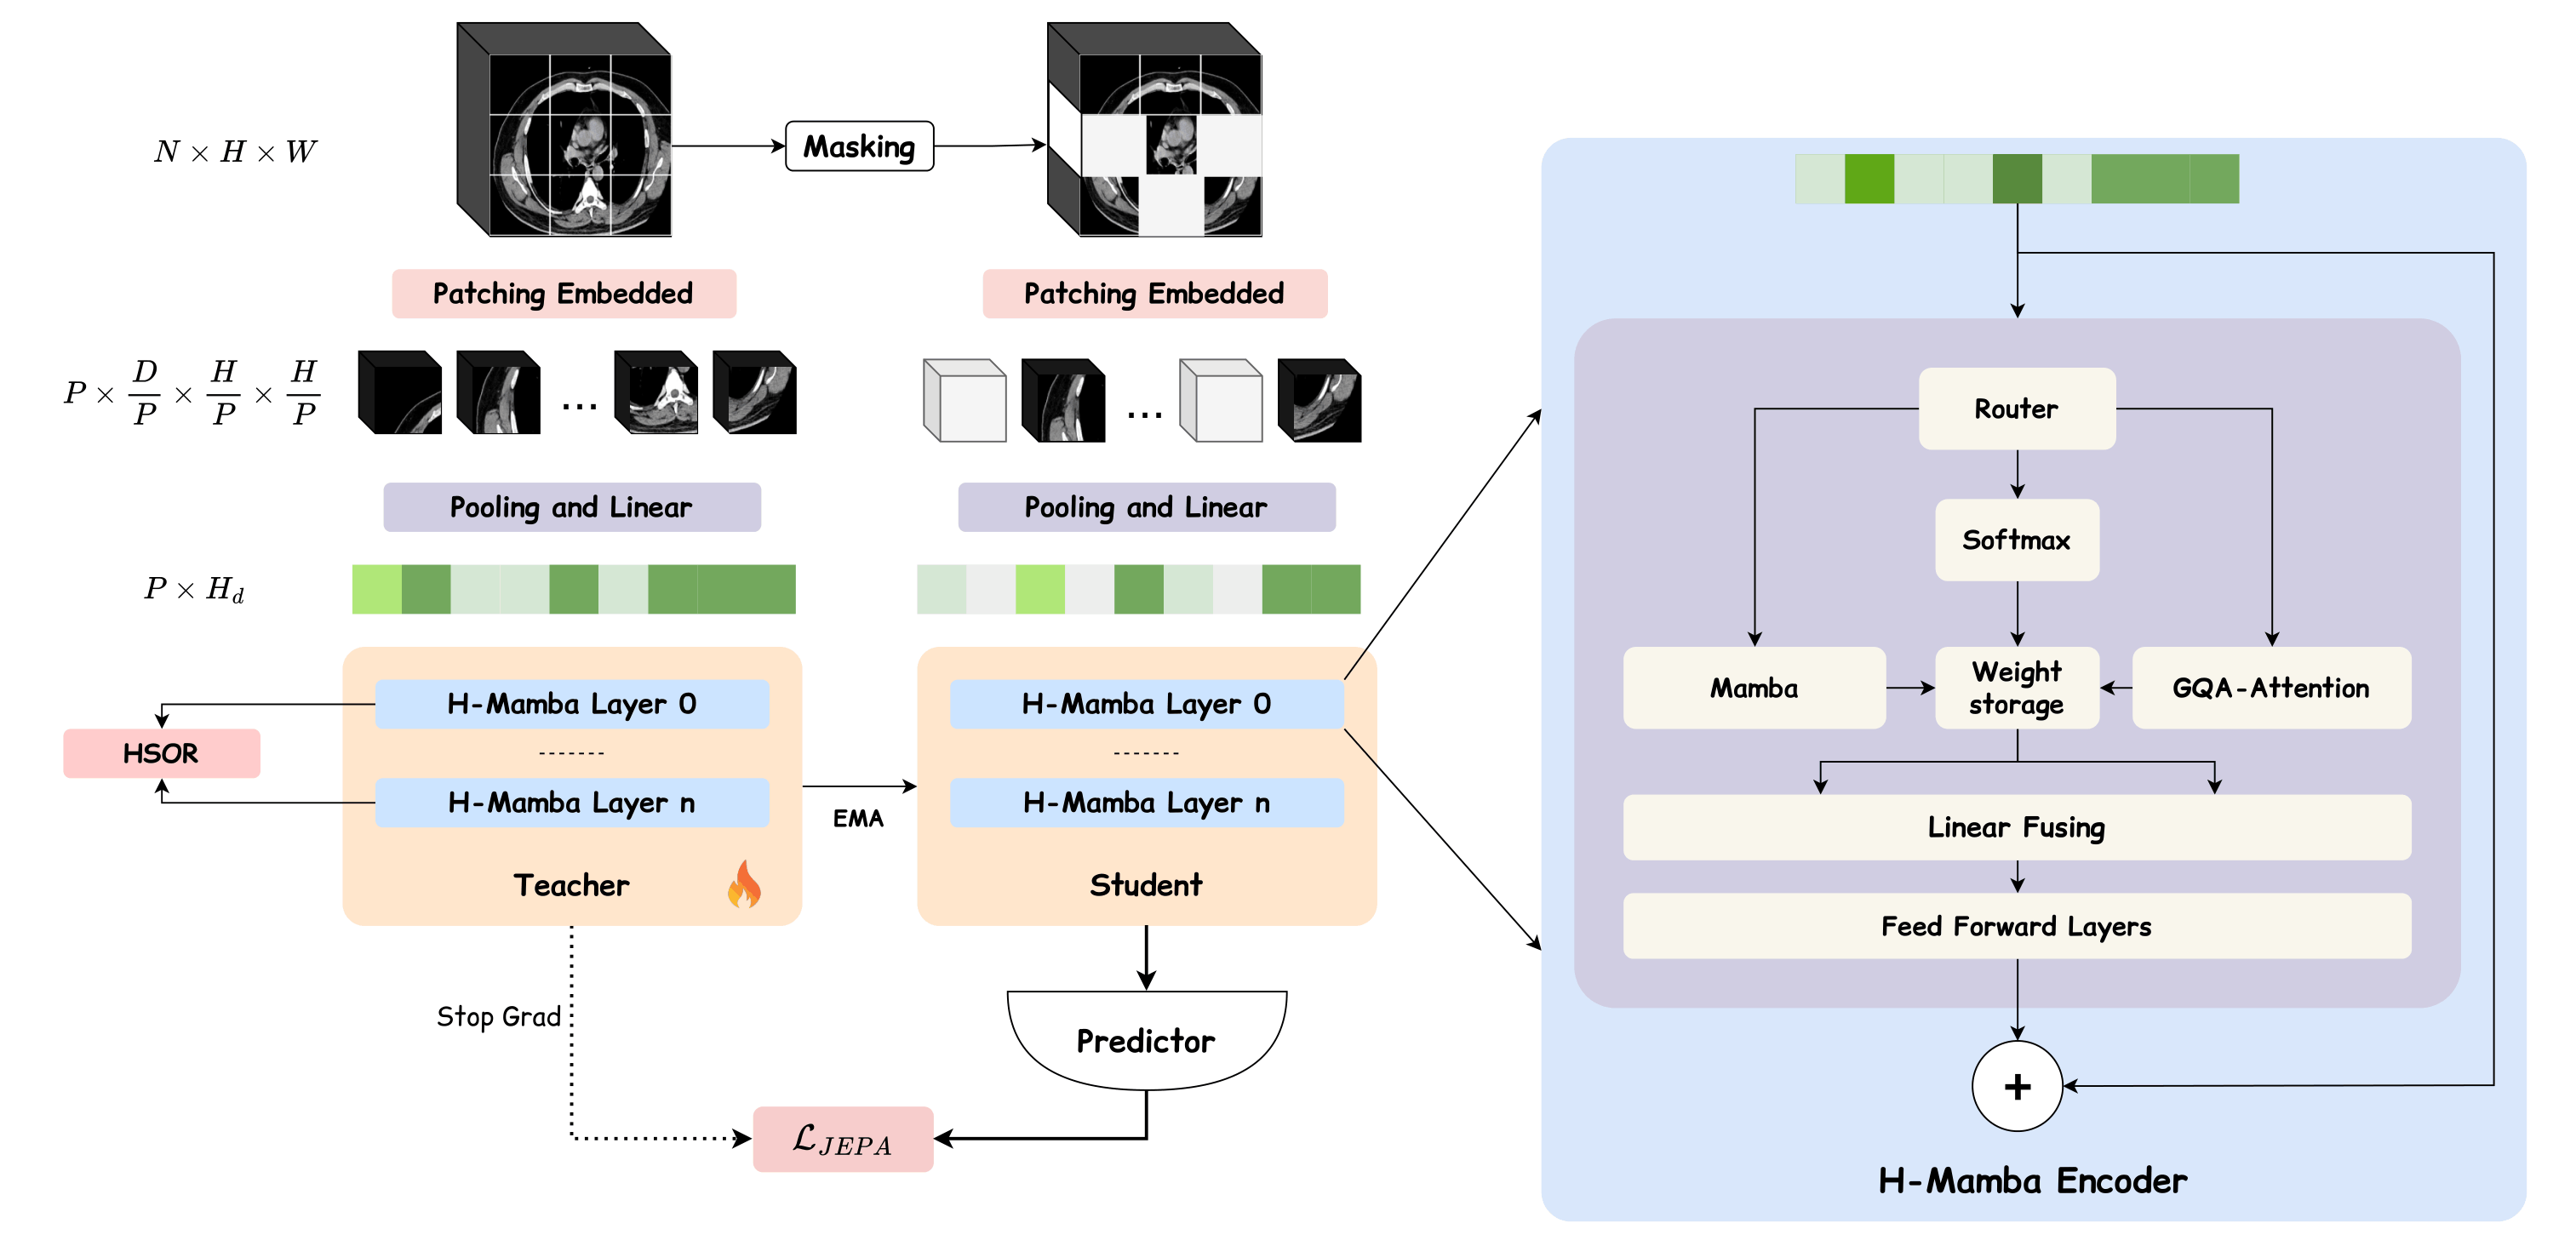

In [3]:
from IPython.display import Image, display

architecture_path = hf_model_dir / "imgs/architecture.png"
if architecture_path.exists():
    display(Image(filename=str(architecture_path)))
else:
    print("Architecture image not found:", architecture_path)

## 1. Carica un volume CT preprocessato

I file `.npy` prodotti da `prepare_radjepa_volumes.py` hanno shape attesa:

```text
[C, D, H, W] = [1, 32, 256, 256]
```

e valori normalizzati in `[0, 1]`.

In [4]:
if input_manifest is None:
    raise FileNotFoundError("Nessun radjepa_npy_manifest.csv trovato. Esegui prima prepare_radjepa_volumes.py.")

manifest = pd.read_csv(input_manifest)
manifest = manifest[manifest["radjepa_status"].isin(["prepared", "exists"])] if "radjepa_status" in manifest.columns else manifest
sample = manifest.iloc[0]
volume_path = sample["radjepa_npy_path"]
if not os.path.isabs(volume_path):
    volume_path = os.path.join(repo_root, volume_path)
volume = np.load(volume_path).astype(np.float32, copy=False)

print("patient_id:", sample.get("patient_id"))
print("timepoint:", sample.get("timepoint"))
print("series_uid:", sample.get("series_uid"))
print("volume_path:", volume_path)
print("volume shape:", volume.shape)
print("dtype:", volume.dtype)
print("min / mean / max:", float(volume.min()), float(volume.mean()), float(volume.max()))

patient_id: 100012
timepoint: T0
series_uid: 1.2.840.113654.2.55.240231128564881525363489796879328810792
volume_path: /ssd2/domenico/datasets/nlst/processed/nlst/pilot_500_balanced/radjepa_npy/100012/100012_T0_1.2.840.113654.2.55.240231128564881525363489796879328810792.npy
volume shape: (1, 32, 256, 256)
dtype: float32
min / mean / max: 0.0 0.3636140525341034 1.0


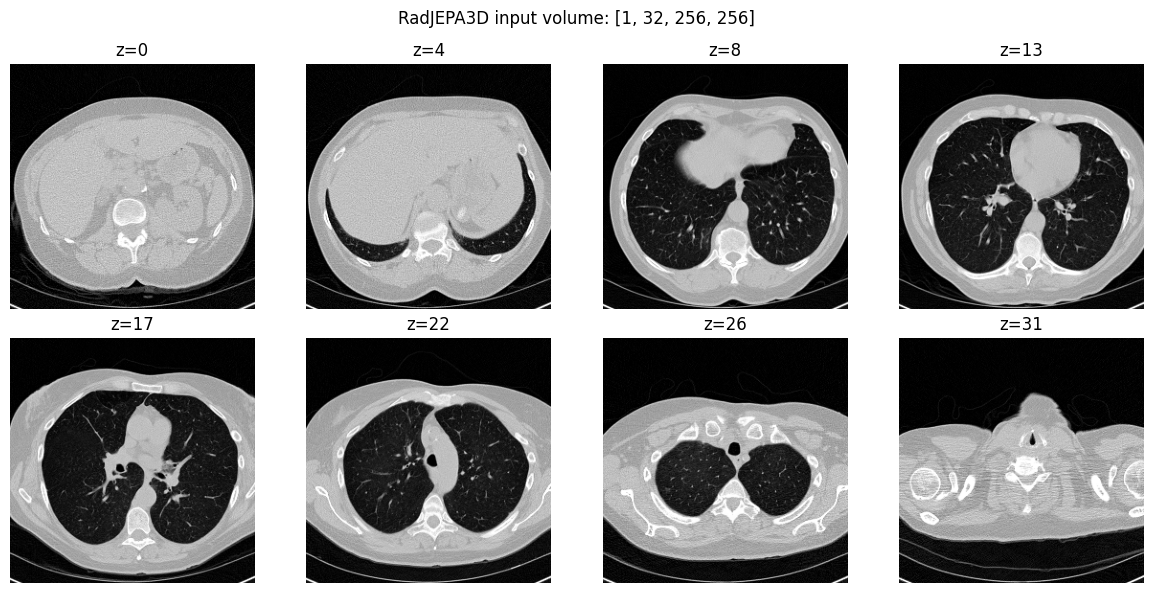

In [5]:
# Visualizza alcune slice assiali del volume preprocessato.
ct = volume[0]
slice_ids = np.linspace(0, ct.shape[0] - 1, 8).astype(int)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, z in zip(axes.ravel(), slice_ids):
    ax.imshow(ct[z], cmap="gray", vmin=0.0, vmax=1.0)
    ax.set_title(f"z={z}")
    ax.axis("off")
fig.suptitle("RadJEPA3D input volume: [1, 32, 256, 256]")
plt.tight_layout()
plt.show()

## 2. Carica RadJEPA3D frozen encoder

Qui usiamo la stessa funzione `build_encoder` della pipeline. Il modello resta in `eval()` e tutti i parametri hanno `requires_grad=False`.

In [6]:
from scripts.extract_radjepa_embeddings import build_encoder

missing = [p for p in [radjepa_code_dir, config_path, checkpoint_path] if not p.exists()]
if missing:
    raise FileNotFoundError("Mancano file/cartelle RadJEPA3D: " + ", ".join(map(str, missing)))

encoder, cfg = build_encoder(
    radjepa_code_dir=radjepa_code_dir,
    config_path=config_path,
    checkpoint_path=checkpoint_path,
    device=device,
)

num_params = sum(p.numel() for p in encoder.parameters())
trainable_params = sum(p.numel() for p in encoder.parameters() if p.requires_grad)

print("encoder:", encoder.__class__.__name__)
print("hidden dim:", cfg.dim)
print("layers:", cfg.n_layers)
print("volume_size:", cfg.volume_size)
print("patch_size:", cfg.patch_size)
print("parameters:", f"{num_params:,}")
print("trainable parameters:", trainable_params)

/home/domenico/lung-jepa-world-model/.venv/lib/python3.10/site-packages/_distutils_hack/__init__.py:53: UserWarning: Reliance on distutils from stdlib is deprecated. Users must rely on setuptools to provide the distutils module. Avoid importing distutils or import setuptools first, and avoid setting SETUPTOOLS_USE_DISTUTILS=stdlib. Register concerns at https://github.com/pypa/setuptools/issues/new?template=distutils-deprecation.yml
  warnings.warn(
/home/domenico/lung-jepa-world-model/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


encoder: MambaEncoder
hidden dim: 384
layers: 12
volume_size: (32, 256, 256)
patch_size: (8, 16, 16)
parameters: 17,188,992
trainable parameters: 0


## 3. Forward pass: volume -> token embeddings

RadJEPA3D restituisce una sequenza di token:

```text
tokens: [B, N, D]
```

dove `N` e il numero di patch/token del volume e `D` e la dimensione latente. Nel nostro setup ci aspettiamo tipicamente `D=384` e fino a `N=1024`.

In [7]:
batch = torch.from_numpy(volume[None]).to(device)  # [B, C, D, H, W]

with torch.inference_mode():
    tokens = encoder(batch, indices=None)
    pooled = tokens.mean(dim=1)

tokens_np = tokens.detach().cpu().numpy().astype(np.float32)
pooled_np = pooled.detach().cpu().numpy().astype(np.float32)

print("input batch shape:", tuple(batch.shape))
print("tokens shape:", tokens_np.shape)
print("pooled shape:", pooled_np.shape)
print("tokens mean/std:", float(tokens_np.mean()), float(tokens_np.std()))
print("pooled mean/std:", float(pooled_np.mean()), float(pooled_np.std()))

np.save(output_dir / "sample_tokens.npy", tokens_np[0])
np.save(output_dir / "sample_pooled.npy", pooled_np[0])
print("saved:", output_dir / "sample_tokens.npy")
print("saved:", output_dir / "sample_pooled.npy")

input batch shape: (1, 1, 32, 256, 256)
tokens shape: (1, 1024, 384)
pooled shape: (1, 384)
tokens mean/std: 0.0034538956824690104 0.19715848565101624
pooled mean/std: 0.0034538963809609413 0.09166916459798813
saved: /home/domenico/lung-jepa-world-model/outputs/notebook_radjepa3d_demo/sample_tokens.npy
saved: /home/domenico/lung-jepa-world-model/outputs/notebook_radjepa3d_demo/sample_pooled.npy


## 4. Guarda cosa c'e dentro i token

Un modo semplice per ispezionare l'output e calcolare la norma L2 di ogni token. Se i token corrispondono alla griglia di patch del volume, possiamo rimapparli in una griglia 3D e visualizzare una heatmap media.

num tokens: 1024
embedding dim: 384
token norm min/mean/max: 3.6338188648223877 3.863374710083008 4.0425944328308105


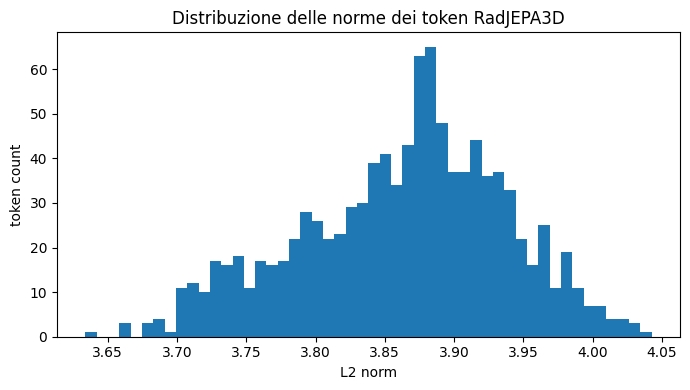

In [8]:
token_matrix = tokens_np[0]  # [N, D]
token_norm = np.linalg.norm(token_matrix, axis=1)

print("num tokens:", token_matrix.shape[0])
print("embedding dim:", token_matrix.shape[1])
print("token norm min/mean/max:", float(token_norm.min()), float(token_norm.mean()), float(token_norm.max()))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(token_norm, bins=50)
ax.set_xlabel("L2 norm")
ax.set_ylabel("token count")
ax.set_title("Distribuzione delle norme dei token RadJEPA3D")
plt.tight_layout()
plt.show()

expected patch grid: (4, 16, 16) product: 1024


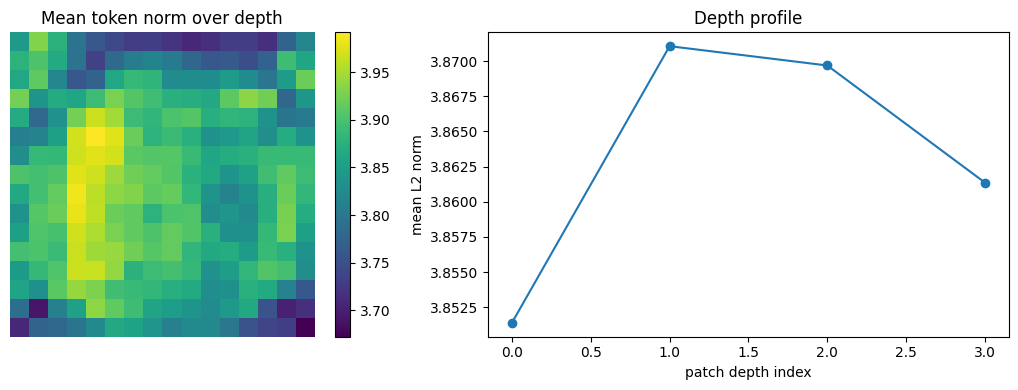

In [9]:
def patch_grid(volume_size, patch_size):
    return tuple(int(v // p) for v, p in zip(volume_size, patch_size))

grid = patch_grid(cfg.volume_size, cfg.patch_size)
print("expected patch grid:", grid, "product:", int(np.prod(grid)))

if int(np.prod(grid)) == token_norm.shape[0]:
    norm_grid = token_norm.reshape(grid)
    heatmap = norm_grid.mean(axis=0)
    depth_profile = norm_grid.mean(axis=(1, 2))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    im = axes[0].imshow(heatmap, cmap="viridis")
    axes[0].set_title("Mean token norm over depth")
    axes[0].axis("off")
    plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

    axes[1].plot(depth_profile, marker="o")
    axes[1].set_title("Depth profile")
    axes[1].set_xlabel("patch depth index")
    axes[1].set_ylabel("mean L2 norm")
    plt.tight_layout()
    plt.show()
else:
    print("La griglia attesa non coincide con N. Mostro solo istogramma e shape dei token.")

## 5. Confronto tra token e pooled embedding

Il predictor puo usare due rappresentazioni:

- `tokens`: sequenza completa `[N, D]`, utile per transformer token-wise;
- `pooled`: media sui token `[D]`, utile per MLP/residual baseline e metriche aggregate.

La relazione e semplicemente:

```python
pooled = tokens.mean(axis=0)
```

manual pooled shape: (384,)
max abs diff vs torch pooled: 2.086162567138672e-07


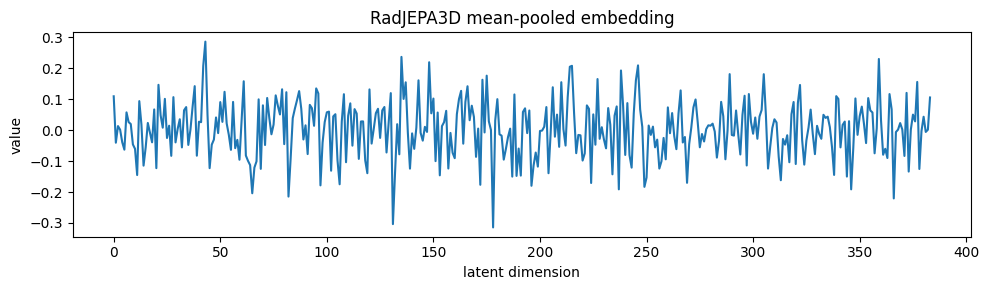

In [10]:
manual_pooled = token_matrix.mean(axis=0)
max_abs_diff = np.max(np.abs(manual_pooled - pooled_np[0]))

print("manual pooled shape:", manual_pooled.shape)
print("max abs diff vs torch pooled:", float(max_abs_diff))

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(pooled_np[0])
ax.set_title("RadJEPA3D mean-pooled embedding")
ax.set_xlabel("latent dimension")
ax.set_ylabel("value")
plt.tight_layout()
plt.show()

## Interpretazione

Questo output e quello che alimenta i nostri esperimenti longitudinali:

- RadJEPA3D e frozen: non lo addestriamo in questa fase.
- Il predictor riceve `z_t`, cioe la rappresentazione della TC al tempo corrente.
- Il target e `z_t+1`, cioe la rappresentazione RadJEPA3D della TC futura.
- La variante transformer token-wise usa direttamente `[N, D]` invece di comprimere subito tutto in `[D]`.

Quindi il cuore del world model e imparare una dinamica latente: predire come dovrebbe cambiare la rappresentazione RadJEPA3D del polmone da uno screening al successivo.